# Vision — Klasifikasi Gambar dengan CNN (fine-tune ResNet18)
**Kapan dipakai:** soal memberi gambar + SATU label kelas per gambar, ada GPU, dan waktu cukup
untuk melatih beberapa epoch. Butuh hasil cepat tanpa melatih jaringan → `klasifikasi_embedding`.
Tidak ada data latih sama sekali → `klasifikasi_clip`. Satu gambar bisa banyak label →
`klasifikasi_multilabel`.

**Bentuk data yang didukung** (pilih satu sel di bagian Baca data):
1. CSV `id,label` + gambar dalam satu folder (aktif)
2. folder per kelas: `train/<kelas>/*.jpg`
3. label tertulis di nama file: `Abyssinian_12.jpg` → `Abyssinian`

**Langkah:** baca tabel → cek label & file gambar → semua gambar jadi RGB 224x224 → split
stratified → fine-tune ResNet18 → F1 macro + confusion matrix + gambar yang salah → latih ulang
di semua data → submission.

**Data demo:** `pets` = foto 10 ras kucing/anjing (Oxford-IIIT Pet). Sengaja kotor: jumlah per
kelas 200 → 30, ukuran 100–3000 px, ada GIF/PNG berekstensi `.jpg`, grayscale, RGBA.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch import nn
from torch.nn import functional
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"              # tidak ada? pakai sample_submission.csv
TRAIN_IMAGE_FOLDER = f"{DATA_FOLDER}/train"
TEST_IMAGE_FOLDER = f"{DATA_FOLDER}/test"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "../../pretrained"
OUTPUT_FOLDER = "../../outputs/vision/klasifikasi_cnn"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar (juga kolom id di submission)
TARGET = "label"        # kolom kelas
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
IMAGE_SIZE = 224        # ukuran input, 160 bila memori/waktu kurang
EPOCHS = 8
BATCH_SIZE = 32         # CUDA out of memory? turunkan ke 16
LEARNING_RATE = 0.0003
VAL_FRACTION = 0.2
SEED = 42
torch.manual_seed(SEED)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

## Baca data — bentuk 1: CSV `id,label` + folder gambar (aktif)
Kolom `path` = lokasi file gambar. `astype(str)` supaya id berupa angka (`101`) juga bisa.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train["path"] = TRAIN_IMAGE_FOLDER + "/" + train[ID_COL].astype(str) + IMAGE_EXTENSION
test["path"] = TEST_IMAGE_FOLDER + "/" + test[ID_COL].astype(str) + IMAGE_EXTENSION
print("train:", train.shape, "| test:", test.shape)
print("contoh path:", train["path"].iloc[0])
train.head()

train: (805, 4) | test: (269, 2)
contoh path: ../../data_latihan/vision/pets/train/Siamese_24.jpg


,id,label,spesies,path
0,Siamese_24.jpg,Siamese,kucing,../../data_latihan/vision/pets/train/Siamese_2...
1,beagle_198.jpg,beagle,anjing,../../data_latihan/vision/pets/train/beagle_19...
2,Abyssinian_204.jpg,Abyssinian,kucing,../../data_latihan/vision/pets/train/Abyssinia...
3,beagle_153.jpg,beagle,anjing,../../data_latihan/vision/pets/train/beagle_15...
4,Abyssinian_72.jpg,Abyssinian,kucing,../../data_latihan/vision/pets/train/Abyssinia...


## (Alternatif) bentuk 2: folder per kelas `train/<kelas>/*.jpg`
Nama subfolder = label. Test biasanya satu folder tanpa label. Hapus `#` untuk memakai.

In [4]:
# rows = []
# for class_name in sorted(os.listdir(TRAIN_IMAGE_FOLDER)):
#     for path in sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/{class_name}/*")):
#         rows.append([os.path.basename(path), class_name, path])
# train = pd.DataFrame(rows, columns=[ID_COL, TARGET, "path"])
# test = pd.DataFrame()
# test["path"] = sorted(glob.glob(f"{TEST_IMAGE_FOLDER}/*"))
# test[ID_COL] = test["path"].apply(os.path.basename)   # cocokkan dengan format sample_submission
# print("train:", train.shape, "| test:", test.shape)

## (Alternatif) bentuk 3: label di nama file `Abyssinian_12.jpg`
`rsplit("_", n=1)` memotong di garis bawah TERAKHIR: `shiba_inu_7` → `shiba_inu`.

In [5]:
# train = pd.DataFrame()
# train["path"] = sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/*"))
# train[ID_COL] = train["path"].apply(os.path.basename)
# train[TARGET] = train[ID_COL].str.rsplit("_", n=1).str[0]
# print(train[TARGET].value_counts())

## EDA: label
Rasio kelas terbanyak/tersedikit > 3 = tidak seimbang: pakai F1 macro, split stratified, dan
`class_weight` di sel latih. Akurasi menipu bila kelas tidak seimbang.

label
Abyssinian                    149
beagle                        135
pug                           120
Persian                       105
Siamese                        82
shiba_inu                      67
Bengal                         53
yorkshire_terrier              41
Egyptian_Mau                   30
staffordshire_bull_terrier     23
Name: count, dtype: int64
jumlah kelas: 10 | rasio terbanyak/tersedikit: 6.5
id ganda: 0 | label kosong: 0


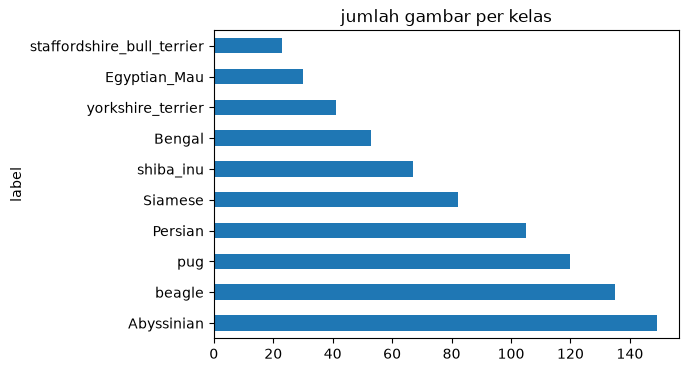

In [6]:
counts = train[TARGET].value_counts()
print(counts)
print("jumlah kelas:", len(counts), "| rasio terbanyak/tersedikit:",
      round(counts.max() / counts.min(), 1))
print("id ganda:", train[ID_COL].duplicated().sum(), "| label kosong:", train[TARGET].isna().sum())
counts.plot.barh(figsize=(6, 4), title="jumlah gambar per kelas")
plt.show()

## EDA: file gambar (ada? format asli? ukuran?)
Ekstensi belum tentu benar: `format` dibaca dari isi file. `mode` RGB = berwarna, L = abu-abu,
RGBA = ada transparansi, P = palet (GIF). Semuanya nanti diubah ke RGB.

In [7]:
def image_info(paths):
    rows = []
    for path in paths:
        if not os.path.exists(path):
            rows.append([path, "TIDAK ADA", "", 0, 0])
            continue
        image = Image.open(path)
        rows.append([path, image.format, image.mode, image.width, image.height])
    return pd.DataFrame(rows, columns=["path", "format", "mode", "width", "height"])


train_info = image_info(train["path"])
test_info = image_info(test["path"])
print("format train:", train_info["format"].value_counts().to_dict())
print("format test :", test_info["format"].value_counts().to_dict())
print("mode train:", train_info["mode"].value_counts().to_dict())
print("mode test :", test_info["mode"].value_counts().to_dict())
sizes = pd.DataFrame()
sizes["train_width"] = train_info["width"].describe()
sizes["test_width"] = test_info["width"].describe()
sizes["train_height"] = train_info["height"].describe()
sizes["test_height"] = test_info["height"].describe()
print(sizes.round())
train_info[(train_info["format"] != "JPEG") | (train_info["mode"] != "RGB")]

format train: {'JPEG': 800, 'GIF': 3, 'PNG': 2}
format test : {'JPEG': 268, 'GIF': 1}
mode train: {'RGB': 800, 'P': 3, 'RGBA': 2}
mode test : {'RGB': 267, 'P': 1, 'L': 1}
       train_width  test_width  train_height  test_height
count        805.0       269.0         805.0        269.0
mean         433.0       445.0         388.0        392.0
std          152.0       145.0         143.0        139.0
min          133.0       150.0         150.0        116.0
25%          333.0       334.0         333.0        333.0
50%          500.0       500.0         375.0        375.0
75%          500.0       500.0         500.0        500.0
max         1886.0      1600.0        2606.0       1600.0


,path,format,mode,width,height
68,../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,300,214
100,../../data_latihan/vision/pets/train/Egyptian_...,PNG,RGBA,183,275
122,../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,183,275
126,../../data_latihan/vision/pets/train/Egyptian_...,GIF,P,246,175
572,../../data_latihan/vision/pets/train/Abyssinia...,PNG,RGBA,200,150


## EDA: lihat contoh gambar per kelas
Cek dengan mata: apakah label masuk akal, objeknya di tengah, ada gambar aneh/salah label.

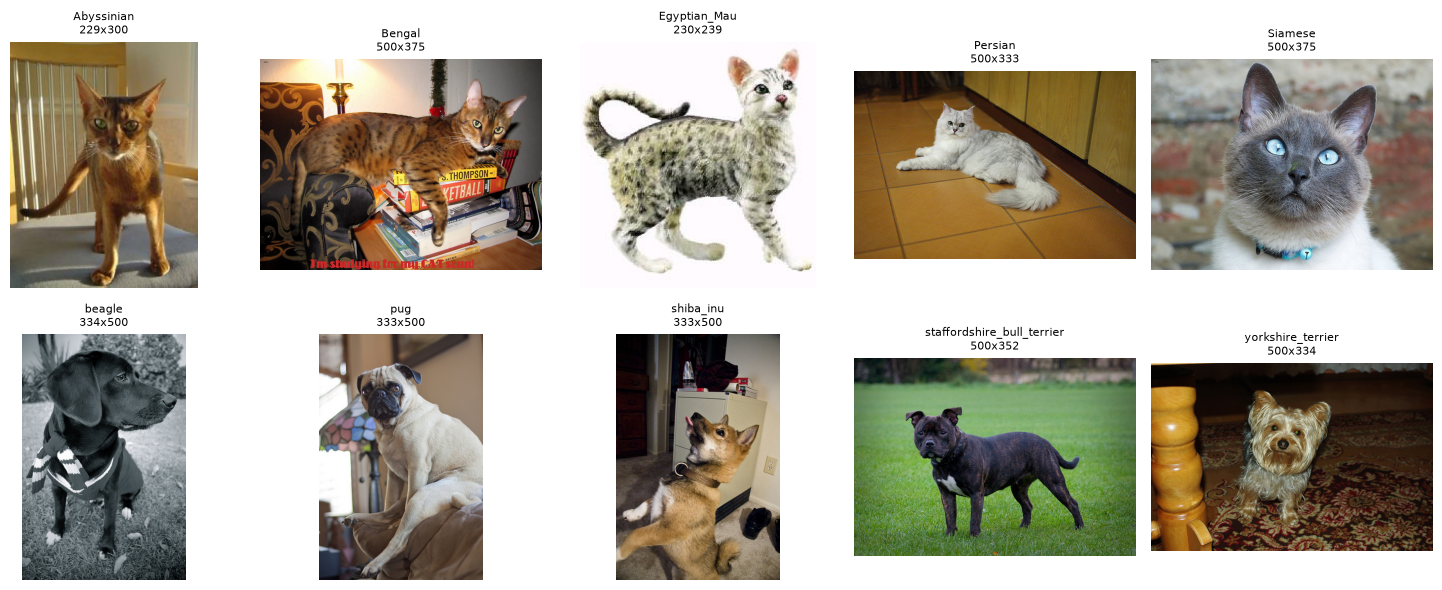

In [8]:
classes = sorted(counts.index)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, class_name in zip(axes.ravel(), classes):
    row = train[train[TARGET] == class_name].iloc[0]
    image = Image.open(row["path"]).convert("RGB")
    ax.imshow(image)
    ax.set_title(f"{class_name}\n{image.width}x{image.height}", fontsize=8)
plt.tight_layout()
plt.show()

## Gambar → tensor
`convert("RGB")` menyamakan semua mode jadi 3 kanal. `ImageOps.fit` memotong bagian tengah
lalu mengecilkan ke persegi `IMAGE_SIZE` (rasio tidak gepeng). Objek sering terpotong di tepi?
Ganti dengan `ImageOps.pad` (menambah bingkai hitam, tidak ada yang terpotong).
Disimpan sebagai uint8 (1 byte/piksel) supaya hemat RAM; dinormalisasi per batch saat latih.

In [9]:
def load_images(paths):
    images = np.zeros((len(paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    for i, path in enumerate(paths):
        image = Image.open(path).convert("RGB")
        images[i] = ImageOps.fit(image, (IMAGE_SIZE, IMAGE_SIZE))
        # images[i] = ImageOps.pad(image, (IMAGE_SIZE, IMAGE_SIZE))
    return torch.tensor(images).permute(0, 3, 1, 2)     # (jumlah, 3, tinggi, lebar)


X_all = load_images(train["path"])
X_test = load_images(test["path"])
print("train:", tuple(X_all.shape), "| test:", tuple(X_test.shape),
      "| RAM:", round((X_all.numel() + X_test.numel()) / 1e9, 2), "GB")

train: (805, 3, 224, 224) | test: (269, 3, 224, 224) | RAM: 0.16 GB


## Split train / validasi (stratified)
Label teks → nomor kelas 0, 1, 2, … (torch butuh angka). `stratify` menjaga proporsi kelas.

In [10]:
encoder = LabelEncoder()
y_numbers = encoder.fit_transform(train[TARGET])
y_all = torch.tensor(y_numbers)
train_rows, val_rows = train_test_split(np.arange(len(y_numbers)), test_size=VAL_FRACTION,
                                        stratify=y_numbers, random_state=SEED)
y_val = y_numbers[val_rows]
print("train:", len(train_rows), "| validasi:", len(val_rows))
print("kelas:", list(encoder.classes_))

train: 644 | validasi: 161
kelas: ['Abyssinian', 'Bengal', 'Egyptian_Mau', 'Persian', 'Siamese', 'beagle', 'pug', 'shiba_inu', 'staffordshire_bull_terrier', 'yorkshire_terrier']


## Model
Pilih SATU blok: hapus `#` di blok yang ingin dipakai, beri `#` pada blok resnet18.
Urutan kekuatan (dan lamanya): resnet18 < efficientnet_b0 < resnet50 < convnext_tiny.

In [11]:
def make_model():
    n_classes = len(encoder.classes_)
    net = models.resnet18(weights=None)
    net.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
    net.fc = nn.Linear(net.fc.in_features, n_classes)

    # net = models.efficientnet_b0(weights=None)
    # net.load_state_dict(torch.load(f"{PRETRAINED}/efficientnet_b0/model.pth"))
    # net.classifier[1] = nn.Linear(net.classifier[1].in_features, n_classes)

    # net = models.convnext_tiny(weights=None)
    # net.load_state_dict(torch.load(f"{PRETRAINED}/convnext_tiny/model.pth"))
    # net.classifier[2] = nn.Linear(net.classifier[2].in_features, n_classes)

    # net = models.resnet50(weights=None)
    # net.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth"))
    # net.fc = nn.Linear(net.fc.in_features, n_classes)
    return net.to(DEVICE)


print(type(make_model()).__name__)

ResNet


## Fungsi latih satu epoch
- Augmentasi: tiap gambar punya peluang 50% dibalik kiri-kanan.
- `class_weight`: kelas jarang diberi bobot loss lebih besar (aktif, karena data demo tidak
  seimbang). Kelas seimbang? Pakai baris `class_weight = None`.

In [12]:
class_weight = (len(y_all) / torch.bincount(y_all).float()).to(DEVICE)
# class_weight = None


def train_one_epoch(net, optimizer, X_part, y_part):
    net.train()
    order = torch.randperm(len(X_part))
    losses = []
    # batch sisa yang tidak penuh dibuang: batch berisi 1 gambar membuat BatchNorm error
    for start in range(0, len(order) - BATCH_SIZE + 1, BATCH_SIZE):
        batch_rows = order[start:start + BATCH_SIZE]
        batch = (X_part[batch_rows].float() / 255 - MEAN) / STD
        flip_rows = torch.rand(len(batch)) < 0.5
        batch[flip_rows] = batch[flip_rows].flip(3)       # balik kiri-kanan
        output = net(batch.to(DEVICE))
        loss = functional.cross_entropy(output, y_part[batch_rows].to(DEVICE), weight=class_weight)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return np.mean(losses)      # rata-rata loss satu epoch

## Latih + pantau F1 validasi tiap epoch
`predict_probabilities` = peluang tiap kelas (softmax), tanpa augmentasi.
F1 masih naik di epoch terakhir → tambah `EPOCHS`. Turun lagi → kurangi (overfit).

In [13]:
def predict_probabilities(net, X_part):
    net.eval()
    batches = []
    with torch.no_grad():
        for start in range(0, len(X_part), 128):
            batch = (X_part[start:start + 128].float() / 255 - MEAN) / STD
            batches.append(functional.softmax(net(batch.to(DEVICE)), dim=1).cpu())
    return torch.cat(batches).numpy()      # (jumlah gambar, jumlah kelas)


net = make_model()
optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)  # lr turun pelan
for epoch in range(EPOCHS):
    loss = train_one_epoch(net, optimizer, X_all[train_rows], y_all[train_rows])
    scheduler.step()
    val_predictions = predict_probabilities(net, X_all[val_rows]).argmax(1)
    val_f1 = f1_score(y_val, val_predictions, average="macro")
    print("epoch", epoch + 1, "| loss", round(loss, 4), "| F1 val", round(val_f1, 4))

epoch 1 | loss 0.7952 | F1 val 0.9105


epoch 2 | loss 0.0986 | F1 val 0.895


epoch 3 | loss 0.0661 | F1 val 0.922


epoch 4 | loss 0.0437 | F1 val 0.898


epoch 5 | loss 0.0226 | F1 val 0.9478


epoch 6 | loss 0.0264 | F1 val 0.9478


epoch 7 | loss 0.0104 | F1 val 0.9478


epoch 8 | loss 0.0081 | F1 val 0.9478


## Evaluasi di validasi
Baca confusion matrix: baris = label asli, kolom = tebakan. Angka di luar diagonal = salah.

akurasi: 0.9689
F1 macro: 0.9478
                            precision    recall  f1-score   support

                Abyssinian       0.91      1.00      0.95        30
                    Bengal       0.90      0.82      0.86        11
              Egyptian_Mau       1.00      0.67      0.80         6
                   Persian       1.00      1.00      1.00        21
                   Siamese       1.00      1.00      1.00        16
                    beagle       1.00      1.00      1.00        27
                       pug       0.96      1.00      0.98        24
                 shiba_inu       1.00      1.00      1.00        13
staffordshire_bull_terrier       1.00      0.80      0.89         5
         yorkshire_terrier       1.00      1.00      1.00         8

                  accuracy                           0.97       161
                 macro avg       0.98      0.93      0.95       161
              weighted avg       0.97      0.97      0.97       161



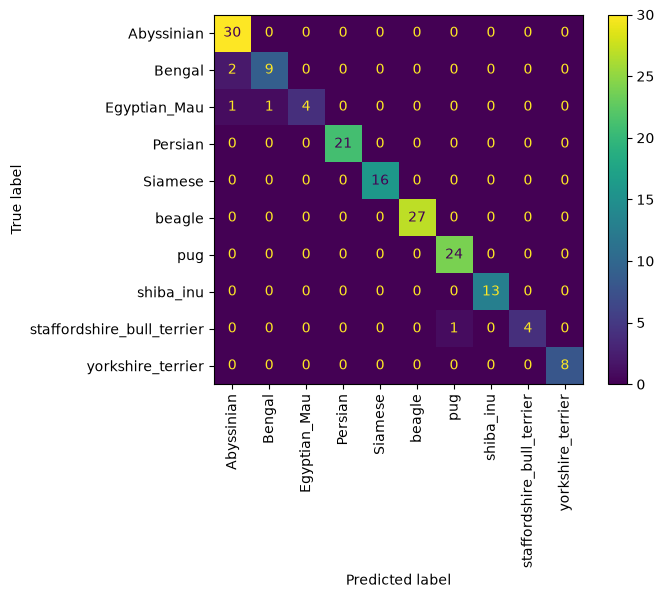

In [14]:
val_probabilities = predict_probabilities(net, X_all[val_rows])
val_predictions = val_probabilities.argmax(1)
print("akurasi:", round((val_predictions == y_val).mean(), 4))
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions, target_names=encoder.classes_))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, display_labels=encoder.classes_,
                                        xticks_rotation=90)
plt.show()

## Lihat gambar yang salah tebak (paling yakin tapi salah dulu)
Polanya sering memberi ide: label soal salah, objek kecil/terpotong, dua kelas memang mirip.

salah: 5 dari 161


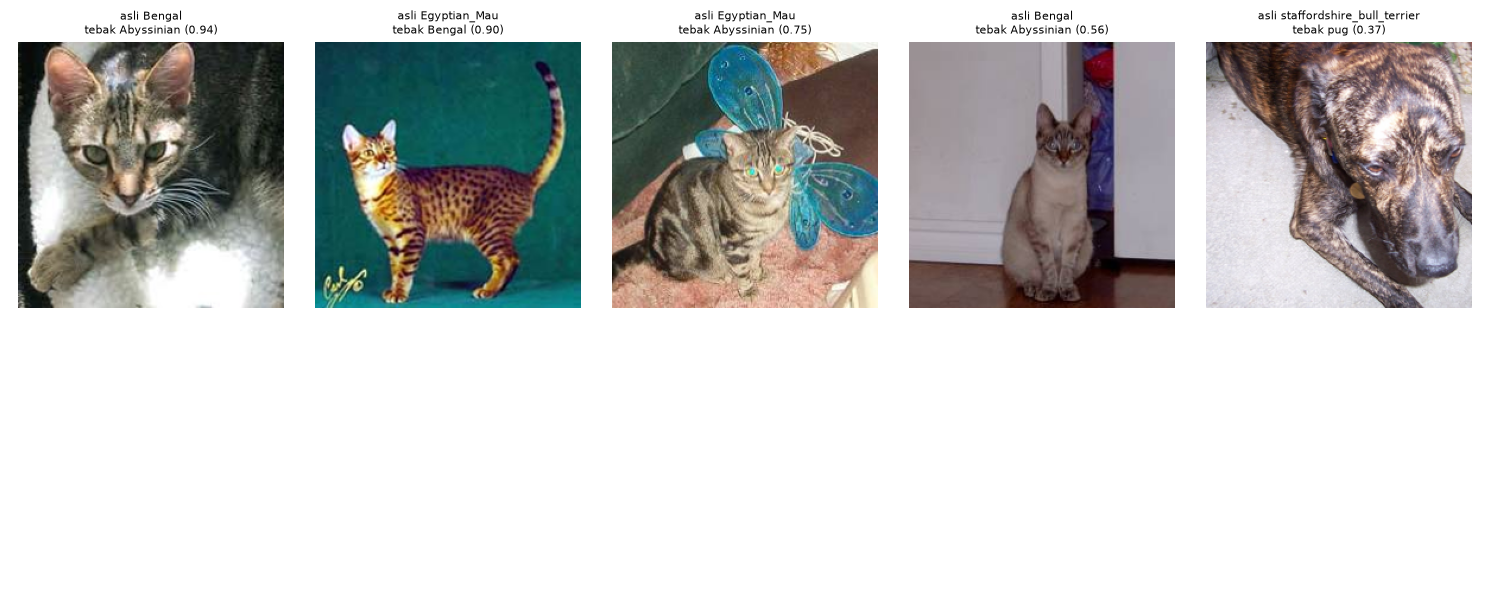

In [15]:
wrong = pd.DataFrame()
wrong["row"] = val_rows
wrong["true"] = encoder.classes_[y_val]
wrong["predicted"] = encoder.classes_[val_predictions]
wrong["confidence"] = val_probabilities.max(1)
wrong = wrong[wrong["true"] != wrong["predicted"]].sort_values("confidence", ascending=False)
print("salah:", len(wrong), "dari", len(val_rows))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, row in zip(axes.ravel(), wrong.head(10).itertuples()):
    ax.imshow(X_all[row.row].permute(1, 2, 0).numpy())
    ax.set_title(f"asli {row.true}\ntebak {row.predicted} ({row.confidence:.2f})", fontsize=8)
plt.tight_layout()
plt.show()

## Latih ulang di SEMUA data train, lalu submission
Format kolom harus sama dengan `sample_submission.csv` (di sini `id,label`, label = nama kelas
asli, bukan nomor; `inverse_transform` mengembalikan nomor → nama).

In [16]:
net = make_model()
optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
for epoch in range(EPOCHS):
    train_one_epoch(net, optimizer, X_all, y_all)
    scheduler.step()
predictions = encoder.inverse_transform(predict_probabilities(net, X_test).argmax(1))

submission = pd.DataFrame()
submission[ID_COL] = test[ID_COL]
submission[TARGET] = predictions
submission.to_csv(f"{OUTPUT_FOLDER}/submission.csv", index=False)
print(submission.shape)
print(submission[TARGET].value_counts())
submission.head()

(269, 2)
label
Abyssinian                    53
beagle                        46
pug                           40
Persian                       35
Siamese                       28
shiba_inu                     23
Bengal                        14
yorkshire_terrier             14
Egyptian_Mau                  10
staffordshire_bull_terrier     6
Name: count, dtype: int64


,id,label
0,test_0001.jpg,pug
1,test_0002.jpg,Egyptian_Mau
2,test_0003.jpg,shiba_inu
3,test_0004.jpg,Abyssinian
4,test_0005.jpg,Siamese


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)

In [17]:
test_key = pd.read_csv(TEST_KEY_CSV)
print("urutan id sama:", (test_key["id"] == submission[ID_COL]).all())
print("F1 macro test:", round(f1_score(test_key["label"], predictions, average="macro"), 4))

urutan id sama: True
F1 macro test: 0.9786


## Masalah umum
- **`FileNotFoundError`:** lihat `contoh path` di sel Baca data. Biasanya `IMAGE_EXTENSION` atau
  nama folder salah. Tabel EDA file menandai `TIDAK ADA`.
- **`UnidentifiedImageError: cannot identify image file`:** file rusak. Cari di tabel EDA file,
  lalu buang barisnya: `train = train[train["path"] != "<path rusak>"]`.
- **`The least populated class in y has only 1 member`:** ada kelas dengan 1 gambar; stratify
  gagal. Buang `stratify=` atau gabungkan kelas langka.
- **`CUDA out of memory`:** `BATCH_SIZE` 32 → 16, atau `IMAGE_SIZE` 224 → 160.
- **RAM penuh saat memuat gambar** (puluhan ribu gambar): turunkan `IMAGE_SIZE` ke 128.
- **F1 val bagus, test jelek:** test berbeda dari train (pencahayaan, sudut). Bandingkan tabel
  ukuran train vs test; lihat beberapa gambar test; tambah augmentasi.
- **Submission ditolak:** cek nama kolom, jumlah baris, dan format id persis `sample_submission`.